# Plots that show outliers beyond three standard deviations

Blue points are within the limits; red points have **|Z-score| > 3**. Horizontal lines mark the mean and **mean ±3SD**

The generic functions in `plot_outliers.py` use the same sample-standard-deviation Z-score formula as `outliers.py`

In [14]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents) if (path / 'plot_outliers.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory.')

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from plot_outliers import calculate_outliers, plot_outliers

cleaned_dir = project_root / 'data' / 'cleaned'
threshold = 3.0


def plot_cleaned_file(filename):
    """Read one cleaned CSV and plot its load column using the generic helper."""
    data = pd.read_csv(cleaned_dir / filename)
    value_columns = [column for column in data.columns if column.endswith('_MW')]
    if len(value_columns) != 1:
        raise ValueError(f'{filename}: expected exactly one load column ending in _MW.')
    value_column = value_columns[0]
    data = data[['Datetime', value_column]].copy()  # Ignore saved CSV index columns.
    result, fig, ax = plot_outliers(
        data, value_column, date_column='Datetime', threshold=threshold,
        title=f'{value_column.removesuffix("_MW")} cleaned hourly load — Z-score outliers',
    )
    mean = result[value_column].mean()
    std = result[value_column].std(ddof=1)
    print(filename)
    print(f'Mean: {mean:,.2f} MW; sample standard deviation: {std:,.2f} MW')
    print(f'Mean ±{threshold:g} SD: [{mean - threshold * std:,.2f}, '
          f'{mean + threshold * std:,.2f}] MW')
    print(f"Outliers: {result['outlier'].sum():,} / {len(result):,} "
          f"({result['outlier'].mean():.2%})")
    plt.show()
    plt.close(fig)
    return result


## AEP

Source: `data/cleaned/AEP_hourly_CLEANED.csv`

AEP_hourly_CLEANED.csv
Mean: 15,499.51 MW; sample standard deviation: 2,591.40 MW
Mean ±3 SD: [7,725.32, 23,273.71] MW
Outliers: 259 / 121,273 (0.21%)


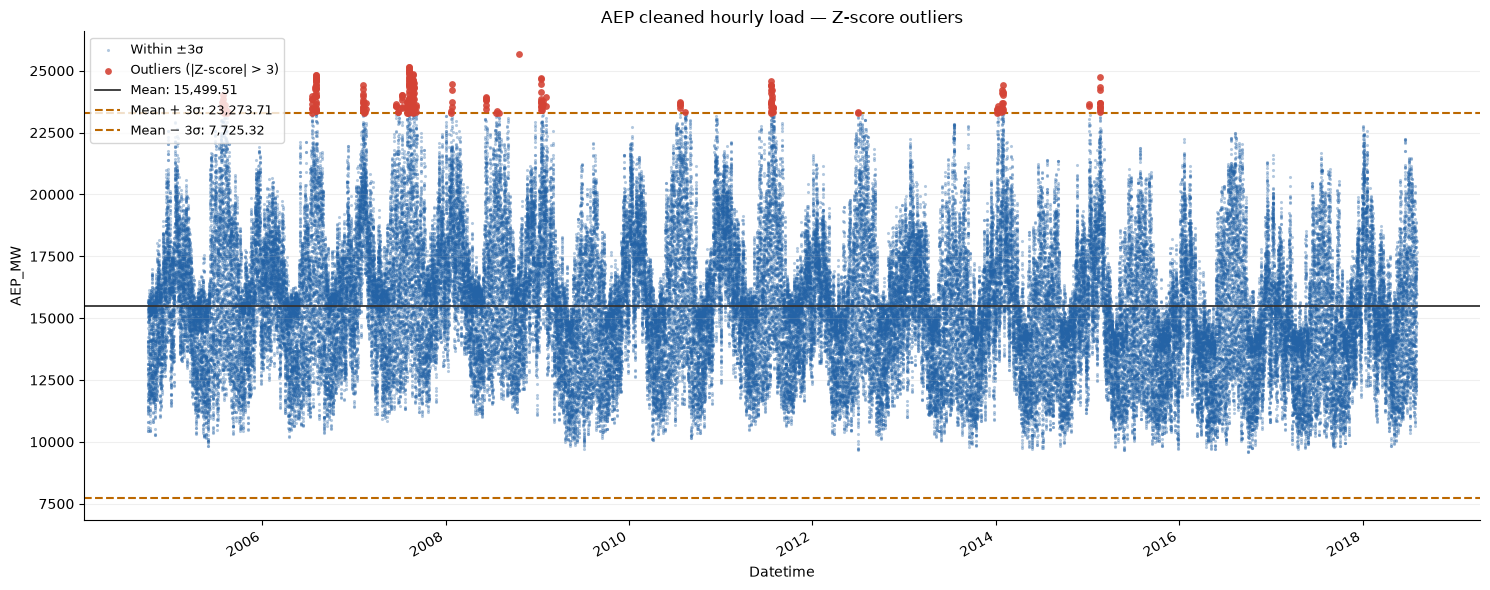

In [15]:
aep = plot_cleaned_file('AEP_hourly_CLEANED.csv')


## COMED

Source: `data/cleaned/COMED_hourly_CLEANED.csv`

COMED_hourly_CLEANED.csv
Mean: 11,420.15 MW; sample standard deviation: 2,304.14 MW
Mean ±3 SD: [4,507.73, 18,332.57] MW
Outliers: 1,011 / 66,497 (1.52%)


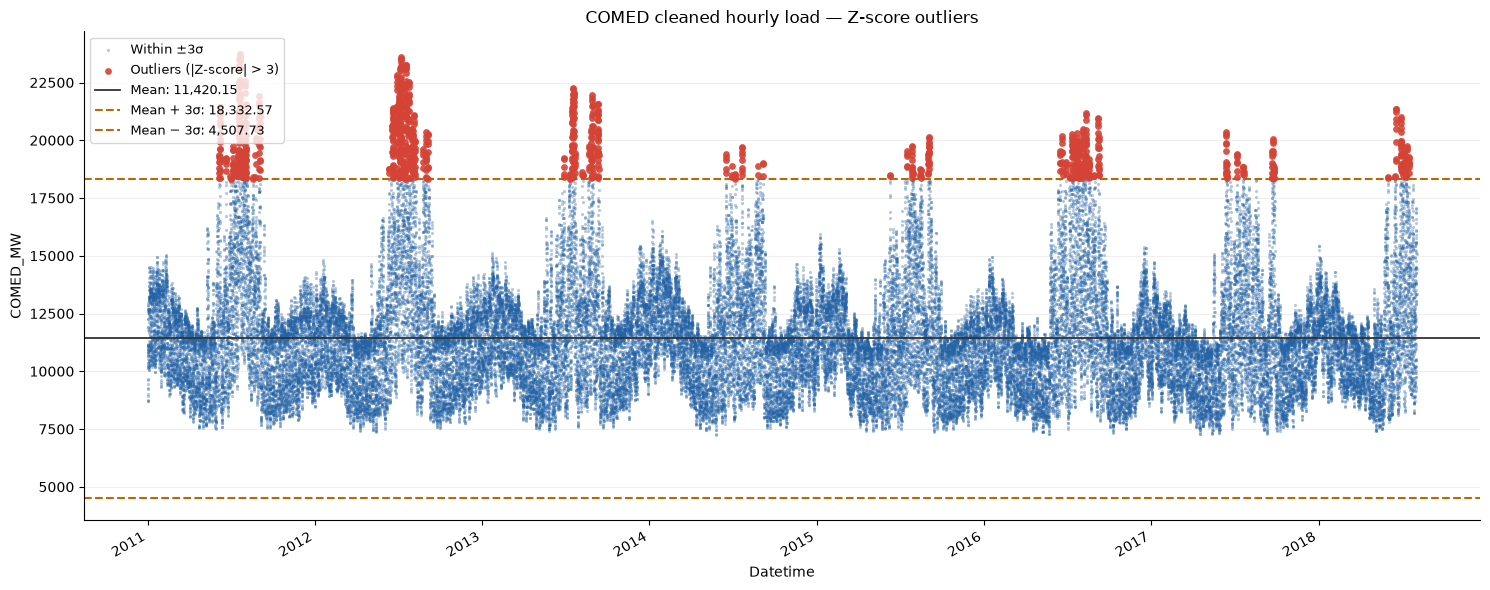

In [16]:
comed = plot_cleaned_file('COMED_hourly_CLEANED.csv')


## DAYTON

Source: `data/cleaned/DAYTON_hourly_CLEANED.csv`

DAYTON_hourly_CLEANED.csv
Mean: 2,037.85 MW; sample standard deviation: 393.40 MW
Mean ±3 SD: [857.64, 3,218.06] MW
Outliers: 699 / 121,275 (0.58%)


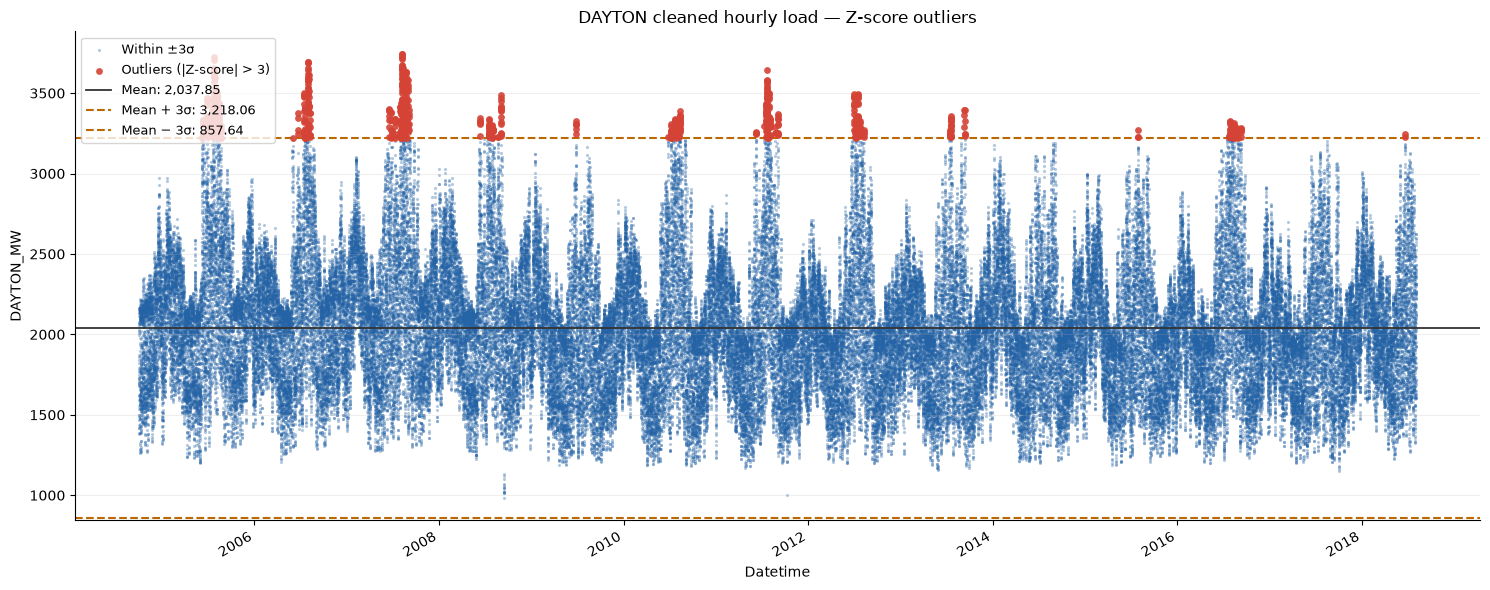

In [17]:
dayton = plot_cleaned_file('DAYTON_hourly_CLEANED.csv')


## DEOK

Source: `data/cleaned/DEOK_hourly_CLEANED.csv`

DEOK_hourly_CLEANED.csv
Mean: 3,105.10 MW; sample standard deviation: 599.86 MW
Mean ±3 SD: [1,305.52, 4,904.67] MW
Outliers: 337 / 57,739 (0.58%)


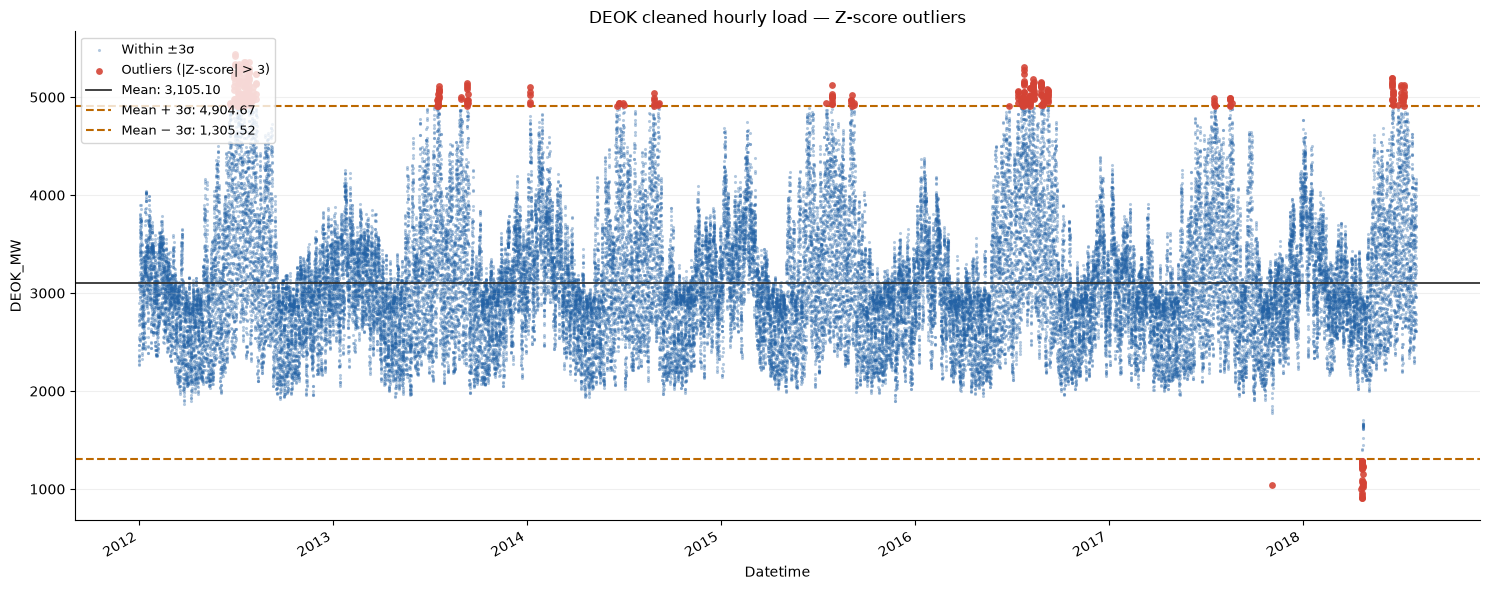

In [18]:
deok = plot_cleaned_file('DEOK_hourly_CLEANED.csv')


## DOM

Source: `data/cleaned/DOM_hourly_CLEANED.csv`

DOM_hourly_CLEANED.csv
Mean: 10,949.20 MW; sample standard deviation: 2,413.95 MW
Mean ±3 SD: [3,707.36, 18,191.04] MW
Outliers: 554 / 116,189 (0.48%)


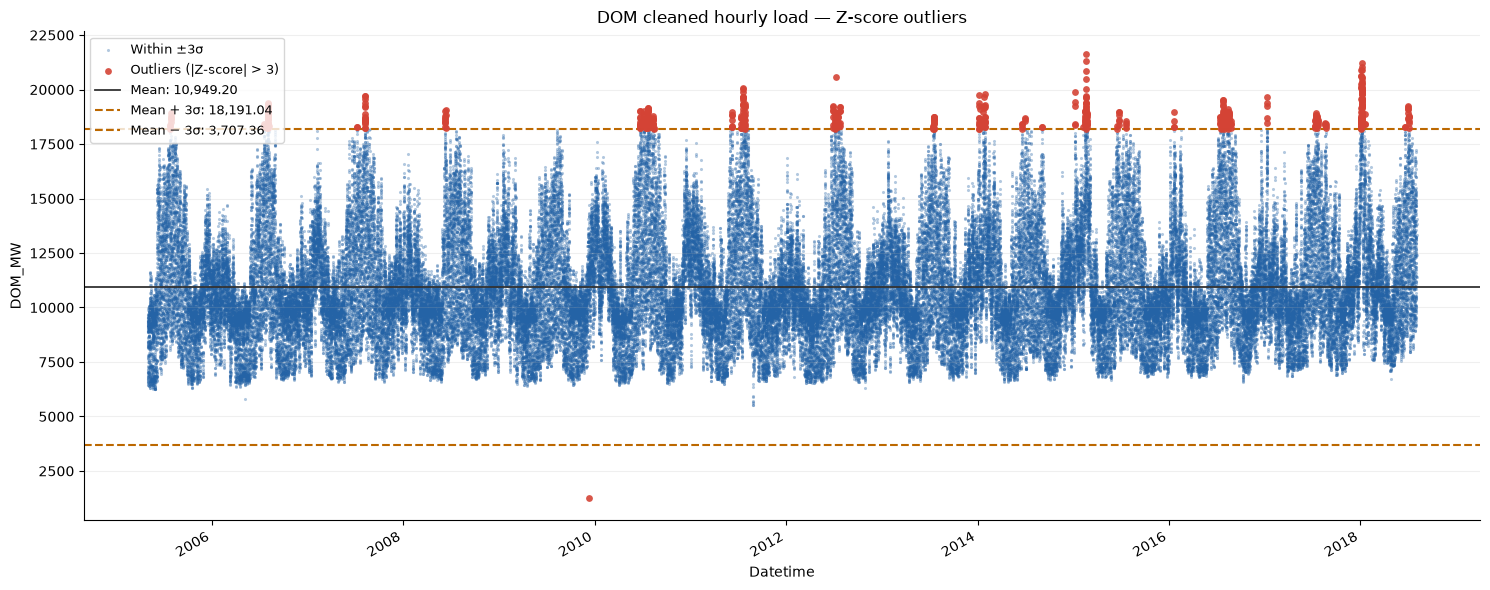

In [19]:
dom = plot_cleaned_file('DOM_hourly_CLEANED.csv')


## DUQ

Source: `data/cleaned/DUQ_hourly_CLEANED.csv`

DUQ_hourly_CLEANED.csv
Mean: 1,658.82 MW; sample standard deviation: 301.74 MW
Mean ±3 SD: [753.60, 2,564.04] MW
Outliers: 1,370 / 119,068 (1.15%)


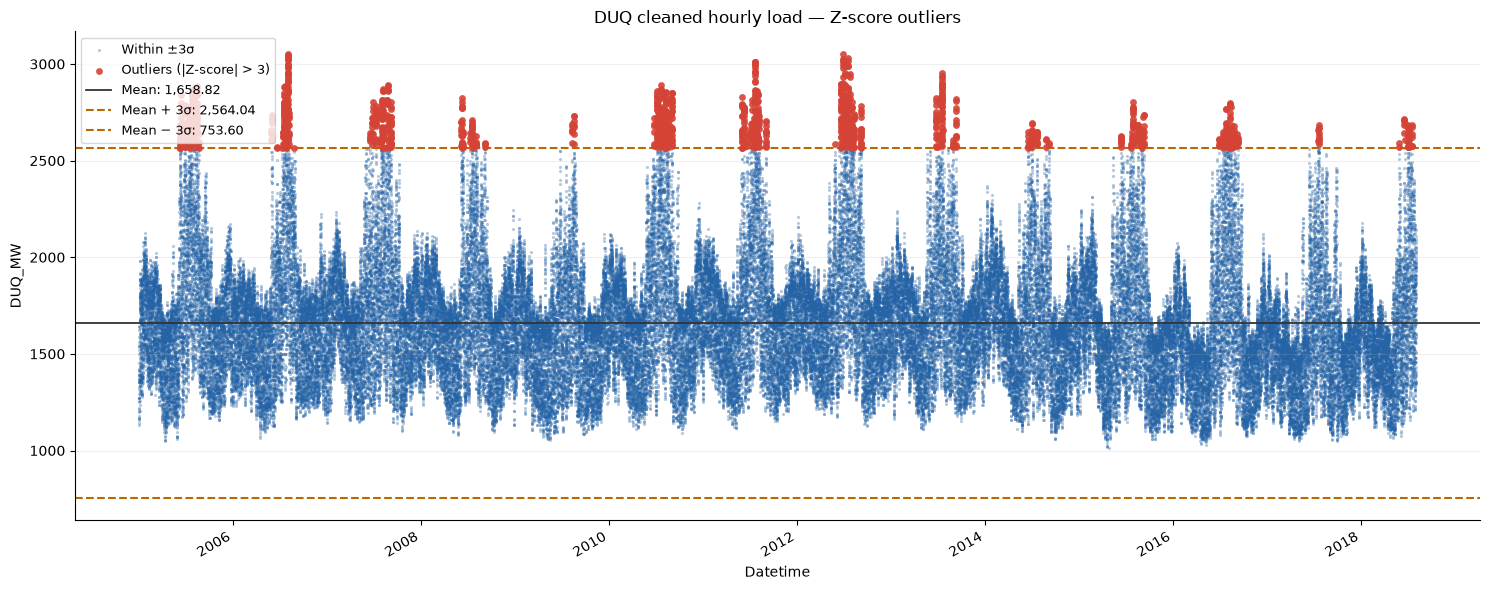

In [20]:
duq = plot_cleaned_file('DUQ_hourly_CLEANED.csv')


## EKPC

Source: `data/cleaned/EKPC_hourly_CLEANED.csv`

EKPC_hourly_CLEANED.csv
Mean: 1,464.22 MW; sample standard deviation: 378.87 MW
Mean ±3 SD: [327.61, 2,600.82] MW
Outliers: 480 / 45,334 (1.06%)


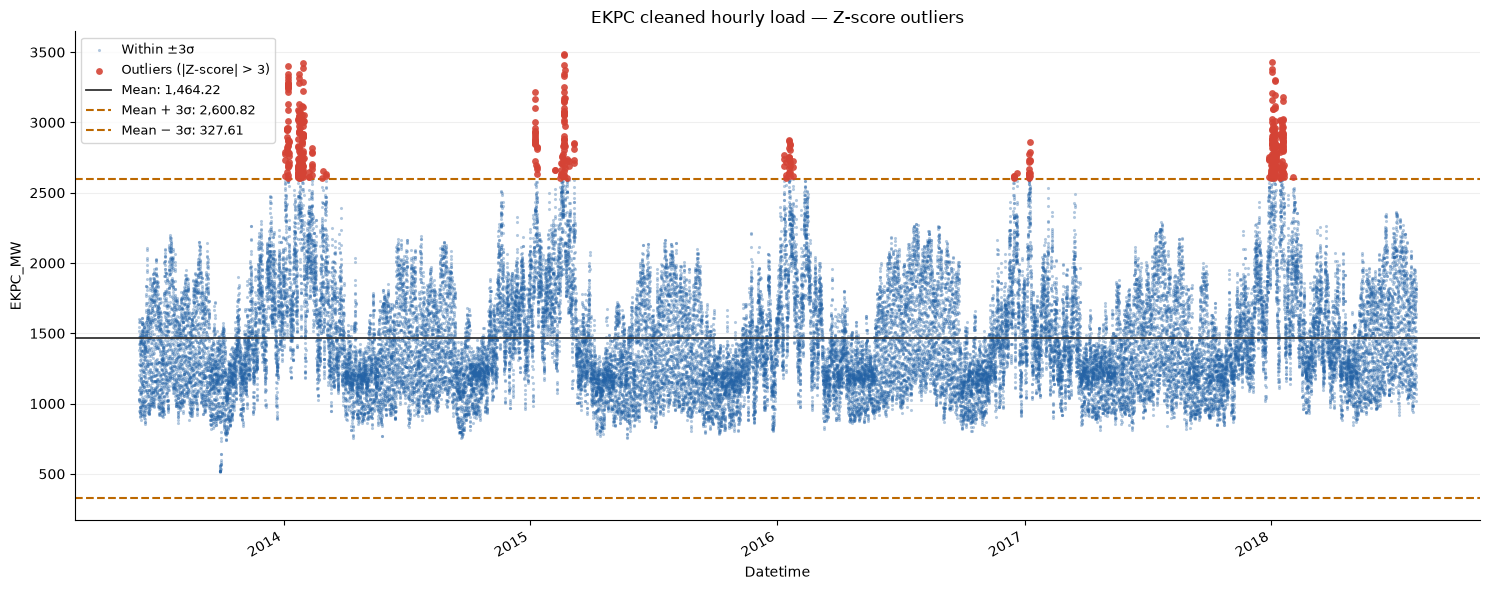

In [21]:
ekpc = plot_cleaned_file('EKPC_hourly_CLEANED.csv')


## FE

Source: `data/cleaned/FE_hourly_CLEANED.csv`

FE_hourly_CLEANED.csv
Mean: 7,792.16 MW; sample standard deviation: 1,331.27 MW
Mean ±3 SD: [3,798.36, 11,785.96] MW
Outliers: 530 / 62,874 (0.84%)


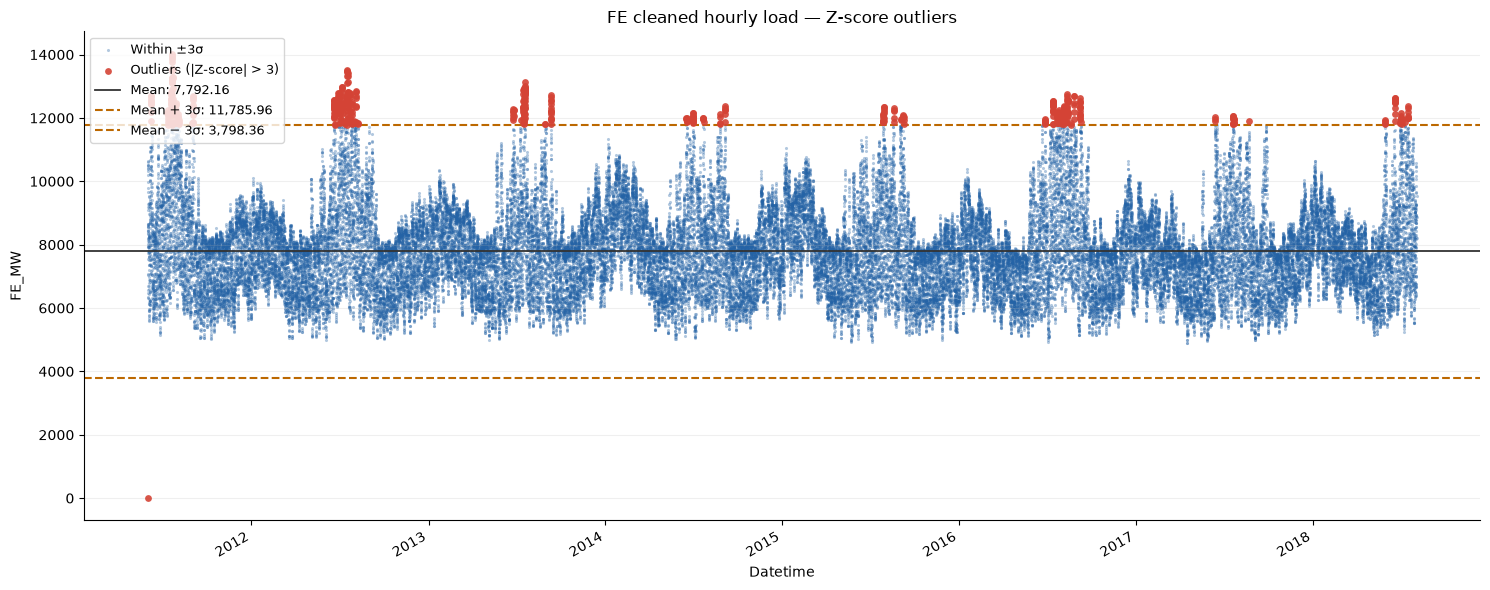

In [22]:
fe = plot_cleaned_file('FE_hourly_CLEANED.csv')


## NI

Source: `data/cleaned/NI_hourly_CLEANED.csv`

NI_hourly_CLEANED.csv
Mean: 11,701.68 MW; sample standard deviation: 2,371.50 MW
Mean ±3 SD: [4,587.19, 18,816.18] MW
Outliers: 785 / 58,450 (1.34%)


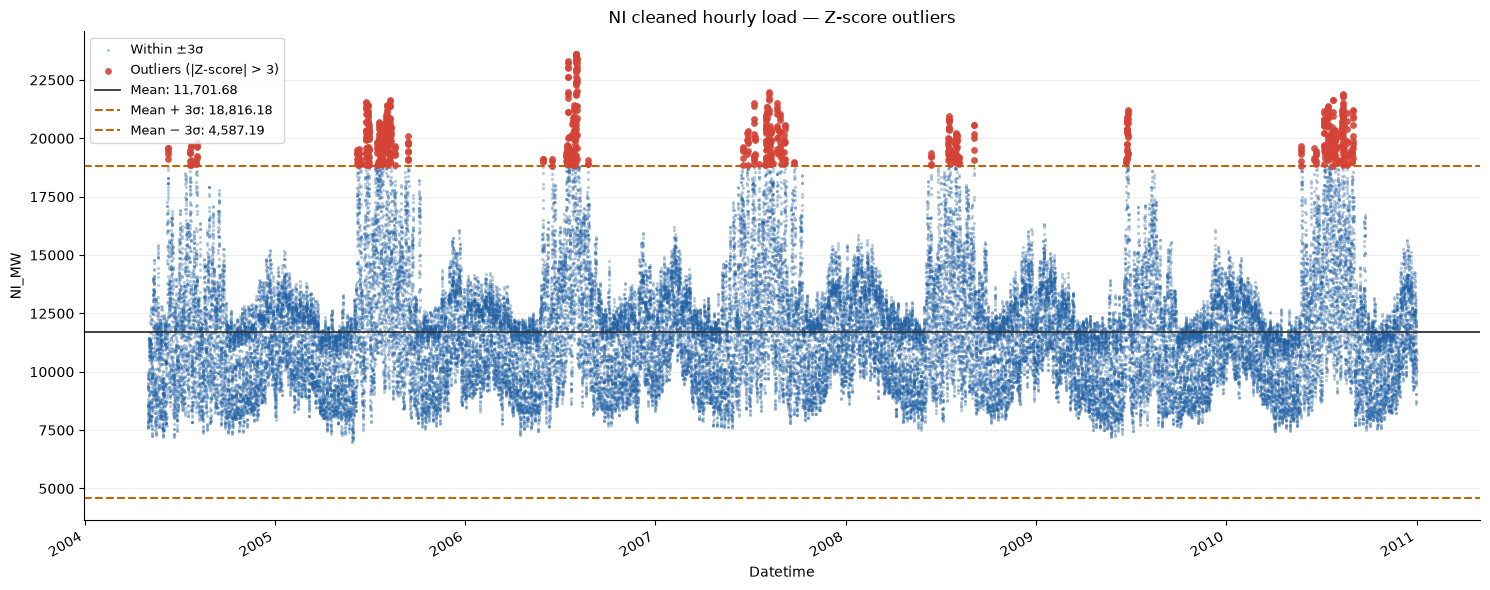

In [23]:
ni = plot_cleaned_file('NI_hourly_CLEANED.csv')


## PJME

Source: `data/cleaned/PJME_hourly_CLEANED.csv`

PJME_hourly_CLEANED.csv
Mean: 32,080.22 MW; sample standard deviation: 6,464.01 MW
Mean ±3 SD: [12,688.19, 51,472.26] MW
Outliers: 1,318 / 145,366 (0.91%)


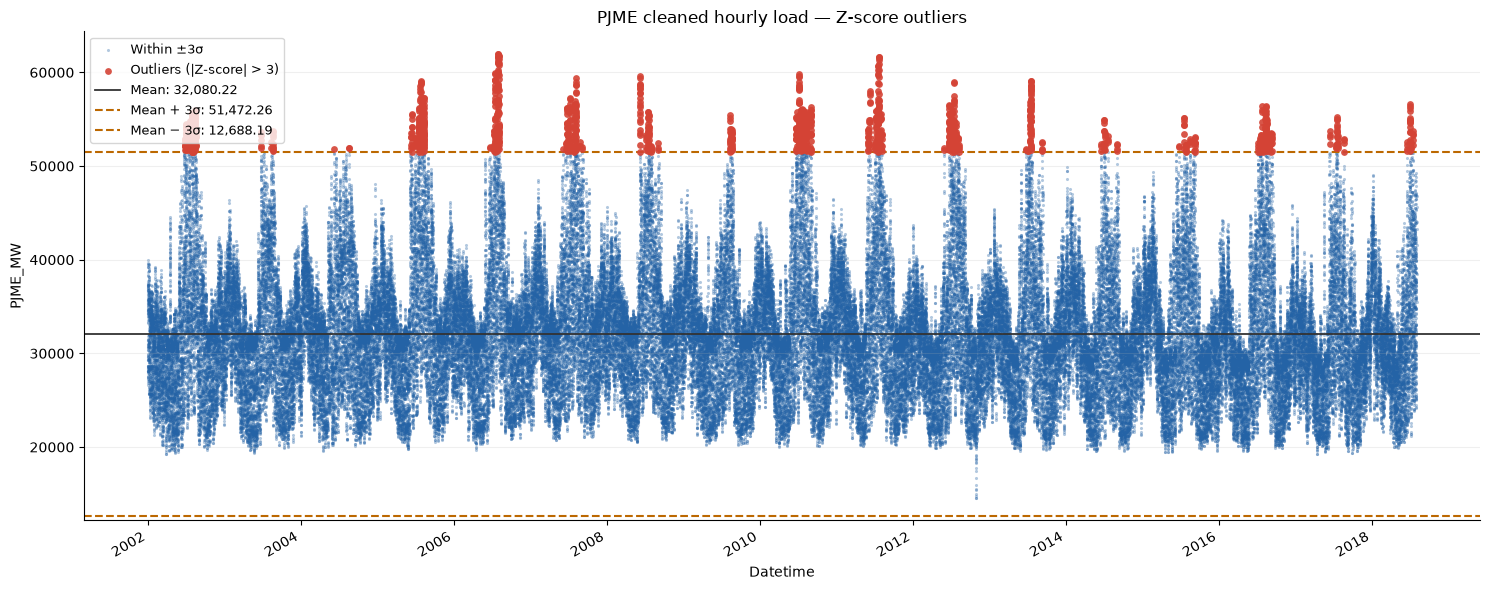

In [24]:
pjme = plot_cleaned_file('PJME_hourly_CLEANED.csv')


## PJM_Load

Source: `data/cleaned/PJM_Load_hourly_CLEANED.csv`

PJM_Load_hourly_CLEANED.csv
Mean: 29,766.43 MW; sample standard deviation: 5,849.77 MW
Mean ±3 SD: [12,217.12, 47,315.74] MW
Outliers: 206 / 32,896 (0.63%)


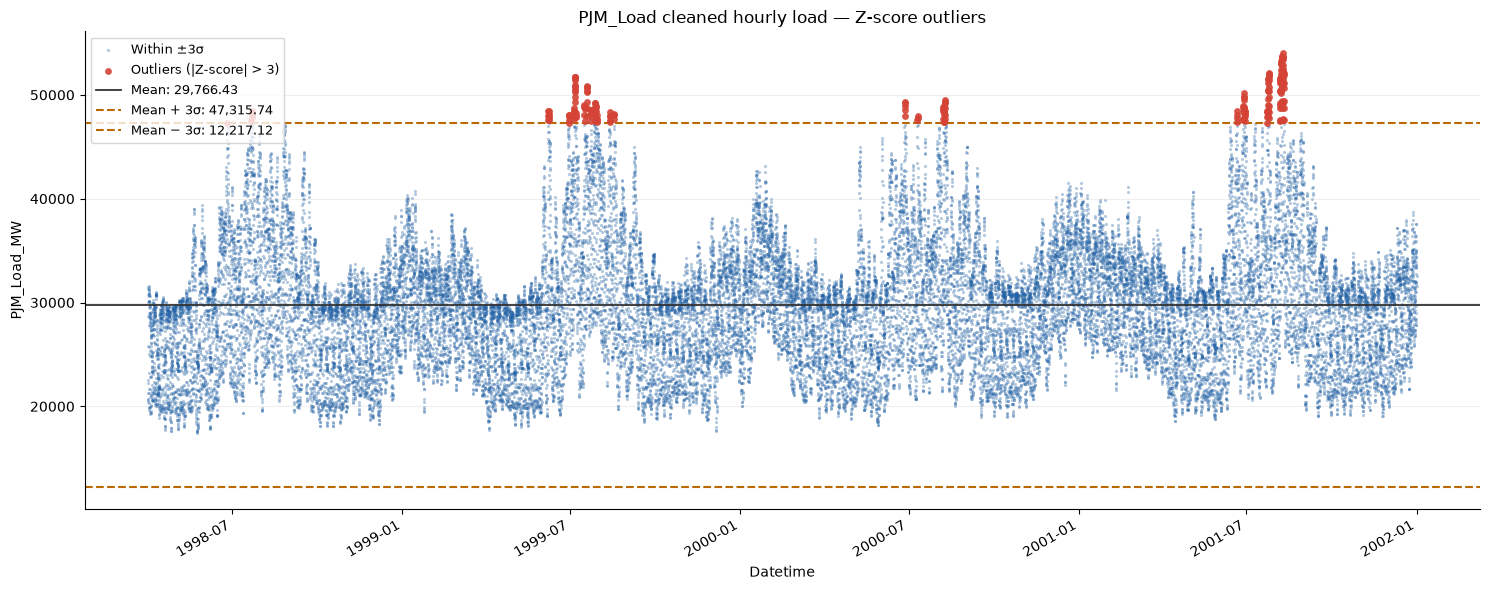

In [25]:
pjm_load = plot_cleaned_file('PJM_Load_hourly_CLEANED.csv')


## PJMW

Source: `data/cleaned/PJMW_hourly_CLEANED.csv`

PJMW_hourly_CLEANED.csv
Mean: 5,602.38 MW; sample standard deviation: 979.14 MW
Mean ±3 SD: [2,664.95, 8,539.80] MW
Outliers: 298 / 143,206 (0.21%)


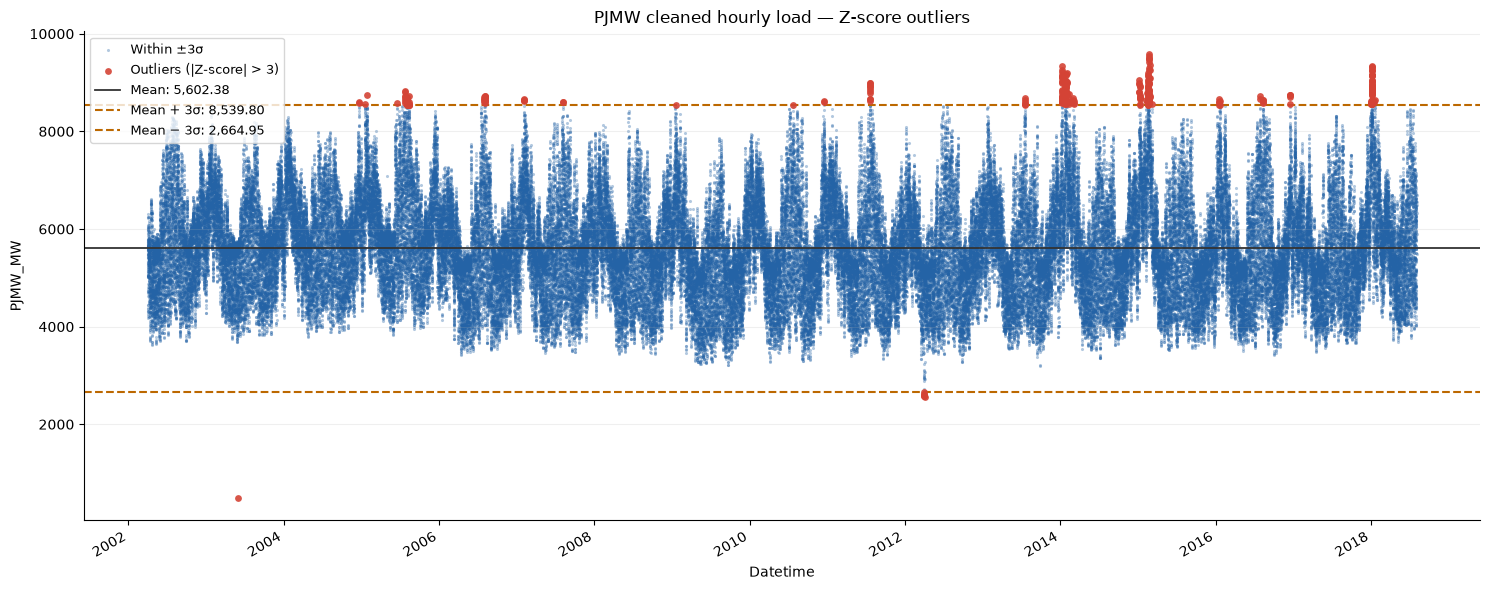

In [26]:
pjmw = plot_cleaned_file('PJMW_hourly_CLEANED.csv')
